# Фазовый сдвиг с нуля

Эта тетрадка — учебник, а не справочник. Каждая глава добавляет **одну** новую мысль.

**Как работать**

1. Запускай клетки по одной сверху вниз: `Shift+Enter`.
2. После каждой картинки читай блок **«Что мы видим»**.
3. Меняй числа в коде и запускай снова: так быстрее всего понять, от чего что зависит.
4. Блоки **«Проверь себя»** — вопросы. Ответ спрятан под стрелкой: сначала подумай сам.

Не нужно проходить всё за раз. Хорошие места для остановки — конец глав 4, 7, 11 и 14.

**Путь**

| Часть | Главы | О чём |
|---|---|---|
| I. Откуда берутся полосы | 1–4 | волна, фаза, интерференция, почему одного кадра мало |
| II. Фазовый сдвиг, когда сдвиги известны | 5–9 | двигаем зеркало, считаем фазу, развёртка, подгонка, ошибки сдвигов |
| III. Сдвиги неизвестны | 10–12 | обратная задача, «качели», ловушки |
| IV. Сдвиг с наклоном | 13–15 | откуда наклон, метод Liu, настоящие кадры |
| Итог | 16 | карта понятий и где это в DigitQt |

In [63]:
# Подготовка: библиотеки и пара помощников для картинок.
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["figure.dpi"] = 90
deg = np.pi / 180          # умножь градусы на deg -> получишь радианы

def show_row(images, titles, cmap="gray", size=3.2, colorbar=False):
    # Несколько картинок в ряд.
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, im, t in zip(np.atleast_1d(axes), images, titles):
        h = ax.imshow(im, cmap=cmap)
        ax.set_title(t)
        ax.axis("off")
        if colorbar:
            fig.colorbar(h, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()

def grid(n=128):
    # Координаты точек детали: от -1 до 1 по x и по y (центр детали — 0).
    x = np.linspace(-1, 1, n)
    return np.meshgrid(x, x)

def wrap(angle):
    # Свернуть угол в диапазон (-pi, pi]: 370° -> 10°, -190° -> 170°.
    return np.angle(np.exp(1j * angle))

print("Готово")

Готово


---
# Часть I. Откуда берутся полосы

## Глава 1. Волна, амплитуда и фаза

Свет — волна. В одной точке пространства поле колеблется:

$$E(t) = a\cos(\omega t + \varphi)$$

- **a** — амплитуда (насколько сильно колеблется);
- **φ** — фаза (*где мы сейчас на волне*).

Удобнее всего представлять волну **стрелкой** длины `a`, которая вращается как стрелка часов; значение поля в момент t — проекция стрелки на горизонтальную ось. Фаза φ — угол, на который стрелка повёрнута в начальный момент.

- фаза 0° — стрелка смотрит вправо, поле максимально;
- 90° — стрелка смотрит вверх, поле равно 0;
- 180° — влево, поле минимально;
- 360° — снова вправо: **круг замкнулся**, от фазы 0° не отличить.

(В учебниках эту стрелку называют *комплексной амплитудой* и пишут `a·e^{iφ}`. Это одно и то же.)

Главное свойство: у двух волн **одной частоты** стрелки вращаются **синхронно**. Угол между ними — *разность фаз* — со временем не меняется. Поэтому стрелки можно рисовать неподвижными. Волны с постоянной разностью фаз называют **когерентными** — именно они интерферируют.

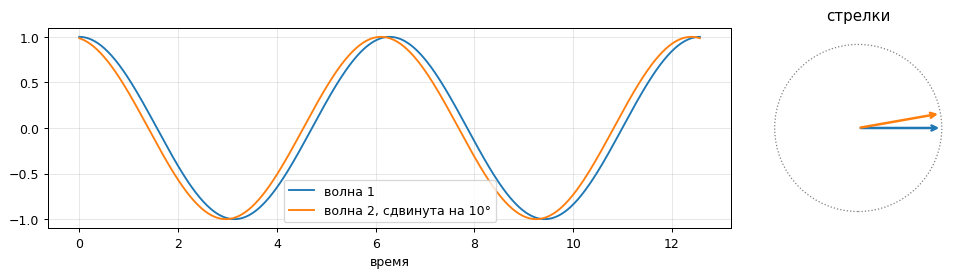

In [64]:
shift = 10 * deg                         # <- разность фаз; поменяй: 0, 45, 180, 360

t = np.linspace(0, 4 * np.pi, 500)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3), gridspec_kw={"width_ratios": [3, 1]})
ax1.plot(t, np.cos(t), label="волна 1")
ax1.plot(t, np.cos(t + shift), label=f"волна 2, сдвинута на {shift/deg:.0f}°")
ax1.set_xlabel("время"); ax1.legend(); ax1.grid(alpha=0.3)

# Те же две волны в виде стрелок
for angle, color in [(0, "C0"), (shift, "C1")]:
    ax2.annotate("", xy=(np.cos(angle), np.sin(angle)), xytext=(0, 0),
                 arrowprops=dict(arrowstyle="->", color=color, lw=2))
ax2.add_patch(plt.Circle((0, 0), 1, fill=False, ls=":", color="gray"))
ax2.set_xlim(-1.2, 1.2); ax2.set_ylim(-1.2, 1.2); ax2.set_aspect("equal"); ax2.axis("off")
ax2.set_title("стрелки")
plt.tight_layout(); plt.show()

**Что мы видим.** Вторая волна — та же, но «раньше» на четверть периода; её стрелка повёрнута на 90°. При сдвиге 360° графики совпадут, и стрелки тоже.

> **Проверь себя.** Чем отличаются волны со сдвигом 30° и 390°?
> <details><summary>ответ</summary>Ничем: стрелка, повёрнутая на 390°, смотрит туда же, куда повёрнутая на 30°. Фаза определена только «по кругу», с точностью до 360°. Эта мысль понадобится ещё много раз.</details>

## Глава 2. Интерференция: складываем стрелки

В интерферометре (у нас — схема Тваймана–Грина) свет делится на два пучка:

- **опорный** отражается от эталона (идеального зеркала);
- **предметный** отражается от детали.

Потом пучки снова складываются, и камера измеряет **интенсивность** суммы.

Пусть в какой-то точке деталь ниже эталона на высоту `h`. Тогда предметный пучок проходит лишний путь `2h` (туда и обратно) и отстаёт по фазе на

$$\varphi = 2\pi \cdot \frac{2h}{\lambda}.$$

Два правила, и больше ничего не нужно:

1. **Интенсивность — квадрат амплитуды:** `I = a²`. Волна с амплитудой 1 даёт интенсивность **I₀ = 1**.
2. **Когерентные волны складываются как стрелки.** Суммарная амплитуда — длина суммы стрелок, а интенсивность — квадрат этой длины.

Сложим две одинаковые стрелки (a₁ = a₂ = 1) при разных разностях фаз.

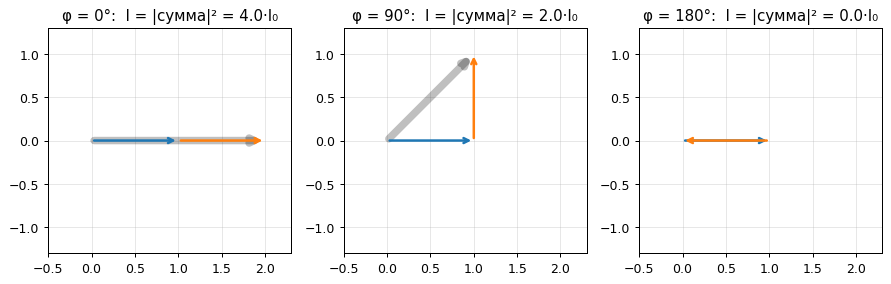

синяя — опорная волна, оранжевая — предметная, широкая серая — их сумма


In [65]:
a1, a2 = 1.0, 1.0                           # амплитуды опорной и предметной волн
I1, I2 = a1**2, a2**2                       # интенсивность каждой по отдельности

def arrow(ax, start, end, color, lw=2, alpha=1.0):
    # Стрелка от точки start к точке end; точки — комплексные числа (x + iy).
    ax.annotate("", xy=(end.real, end.imag), xytext=(start.real, start.imag),
                arrowprops=dict(arrowstyle="->", color=color, lw=lw, alpha=alpha))

fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, phi in zip(axes, [0, 90 * deg, 180 * deg]):
    w1 = a1 * np.exp(1j * 0)                # стрелка = комплексное число: длина a, угол φ
    w2 = a2 * np.exp(1j * phi)
    total = w1 + w2                         # сложение стрелок
    arrow(ax, 0j, total, "k", lw=6, alpha=0.25)   # сумма (широкая серая)
    arrow(ax, 0j, w1, "C0")                       # опорная
    arrow(ax, w1, w1 + w2, "C1")                  # предметная — пристроена к концу опорной
    ax.set_xlim(-0.5, 2.3); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.set_title(f"φ = {phi/deg:.0f}°:  I = |сумма|² = {abs(total)**2:.1f}·I₀")
plt.tight_layout(); plt.show()
print("синяя — опорная волна, оранжевая — предметная, широкая серая — их сумма")

**Что мы видим.**

- φ = 0°: стрелки в одну сторону, сумма длиной 2 → интенсивность **4·I₀**. Это то самое «в четыре раза ярче одной волны».
- φ = 90°: сумма — гипотенуза, длина √2 → **2·I₀**.
- φ = 180°: стрелки навстречу, сумма 0 → **темнота**.

Длину суммы двух стрелок даёт теорема косинусов. Отсюда учебниковая формула интерференции:

$$I = I_1 + I_2 + \underbrace{2\sqrt{I_1 I_2}\,\cos\varphi}_{\text{интерференционный член}}$$

Без интерференционного члена (если бы пучки были некогерентными) интенсивность была бы просто `I₁ + I₂` — здесь 2·I₀ в любой точке. Проверим формулу против сложения стрелок для всех φ.

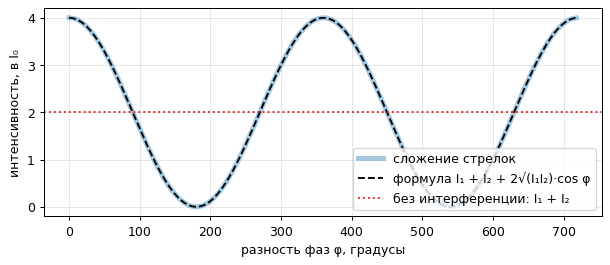

в среднем по всем φ: 2.0   = I₁ + I₂ = 2.0


In [66]:
phis = np.linspace(0, 4 * np.pi, 400, endpoint=False)   # два полных оборота
I_arrows = np.abs(a1 + a2 * np.exp(1j * phis))**2               # сложение стрелок
I_formula = I1 + I2 + 2 * np.sqrt(I1 * I2) * np.cos(phis)        # учебниковая формула

plt.figure(figsize=(8, 3))
plt.plot(phis / deg, I_arrows, lw=4, alpha=0.4, label="сложение стрелок")
plt.plot(phis / deg, I_formula, "k--", label="формула I₁ + I₂ + 2√(I₁I₂)·cos φ")
plt.axhline(I1 + I2, color="C3", ls=":", label="без интерференции: I₁ + I₂")
plt.xlabel("разность фаз φ, градусы"); plt.ylabel("интенсивность, в I₀")
plt.legend(loc="lower right"); plt.grid(alpha=0.3); plt.show()
print("в среднем по всем φ:", round(I_arrows.mean(), 3), "  = I₁ + I₂ =", I1 + I2)

**Что мы видим.** Формула и стрелки совпадают. Интенсивность ходит от 0 до 4·I₀, а **в среднем** равна `I₁ + I₂` — красной линии. Интерференция не создаёт и не уничтожает энергию, она её **перераспределяет**: в светлых полосах вдвое больше, чем без интерференции, в тёмных — ноль.

> **Сноска для любопытных.** Настоящее поле — колеблющийся косинус, и камера видит его квадрат, *усреднённый по времени*. Среднее от cos² равно ½, поэтому, если считать «по-честному», все интенсивности выйдут вдвое меньше: одна волна ½, пик 2 вместо 4. Этот общий множитель ½ одинаков для всего и ни на что не влияет, поэтому в учебниках его опускают и пишут `I = a²`. Если где-то встретишь «2» вместо «4», это та же картина в других единицах.

### Как это записывают в фазовом сдвиге

Обозначим две постоянные части формулы буквами:

$$A = I_1 + I_2, \qquad B = 2\sqrt{I_1 I_2} \qquad\Longrightarrow\qquad \boxed{I = A + B\cos\varphi}$$

- **A** — фон: средняя интенсивность;
- **B** — размах колебаний вокруг фона (контраст полос);
- **φ** — то, что мы хотим измерить: в ней спрятана высота детали.

Это главная формула всей тетрадки. Отношение `V = B / A` называют **видностью** полос: 1 — полосы во весь размах, 0 — полос нет.

На практике отражение от детали обычно слабее, чем от эталона. Посмотрим, что меняется при неравных пучках.

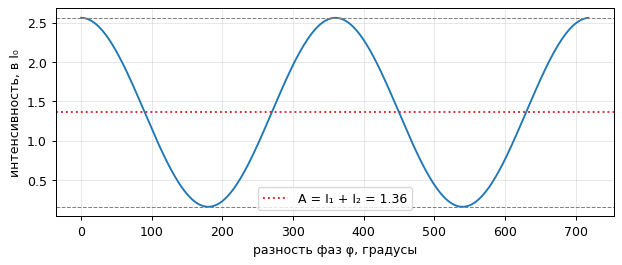

I₁ = 1.00, I₂ = 0.36  ->  A = 1.36, B = 1.20, видность V = B/A = 0.88
максимум A + B = 2.56 = (a₁ + a₂)²,   минимум A − B = 0.16 = (a₁ − a₂)²


In [67]:
a1, a2 = 1.0, 0.6                           # <- предметная волна слабее; попробуй 0.1 и 1.0
I1, I2 = a1**2, a2**2
A_, B_ = I1 + I2, 2 * np.sqrt(I1 * I2)
I_curve = A_ + B_ * np.cos(phis)

plt.figure(figsize=(8, 3))
plt.plot(phis / deg, I_curve)
plt.axhline(A_, color="C3", ls=":", label=f"A = I₁ + I₂ = {A_:.2f}")
plt.axhline(A_ + B_, color="gray", ls="--", lw=0.8)
plt.axhline(A_ - B_, color="gray", ls="--", lw=0.8)
plt.xlabel("разность фаз φ, градусы"); plt.ylabel("интенсивность, в I₀")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print(f"I₁ = {I1:.2f}, I₂ = {I2:.2f}  ->  A = {A_:.2f}, B = {B_:.2f}, видность V = B/A = {B_/A_:.2f}")
print(f"максимум A + B = {A_ + B_:.2f} = (a₁ + a₂)²,   минимум A − B = {A_ - B_:.2f} = (a₁ − a₂)²")

**Что мы видим.** При слабой предметной волне тёмные полосы уже не чёрные: минимум `(a₁ − a₂)² = 0,16`, а не 0. Видность падает. Но полосы видны, даже когда предметный пучок в 10 раз слабее по амплитуде (в 100 раз по интенсивности) — попробуй `a2 = 0.1`.

> **Проверь себя.** Чему равна видность, если предметный пучок полностью перекрыт (a₂ = 0)? А если пучки равны?
> <details><summary>ответ</summary>a₂ = 0: B = 0, V = 0 — полос нет, только ровный фон. Равные пучки: B = A, V = 1 — тёмные полосы совсем чёрные.</details>

## Глава 3. Интерферограмма — карта фазы, «свёрнутая» в косинус

У детали в каждой точке своя высота → своя фаза φ(x, y). Камера показывает `A + B·cos φ(x, y)` во всех точках сразу — это и есть **интерферограмма**.

Камера измеряет интенсивность в своих единицах — уровнях яркости 0…255. Дальше в тетрадке возьмём фон **A = 120** и размах **B = 80** уровней. Из формул главы 2 можно найти, каким пучкам это соответствует.

Возьмём деталь-«чашу»: в центре глубже всего, к краям мельче.

это пучки с интенсивностью 105 и 15 уровней; полосы от 40 до 200, видность 0.67


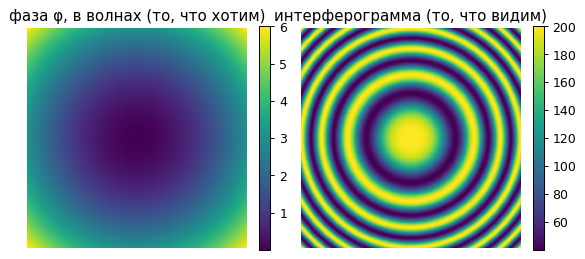

In [68]:
A, B = 120, 80                                # фон и размах полос, уровни яркости камеры
I_ref = (A + np.sqrt(A**2 - B**2)) / 2        # обратно из A = I₁ + I₂, B = 2√(I₁I₂)
I_obj = (A - np.sqrt(A**2 - B**2)) / 2
print(f"это пучки с интенсивностью {I_ref:.0f} и {I_obj:.0f} уровней; "
      f"полосы от {A - B} до {A + B}, видность {B / A:.2f}")

X, Y = grid(200)
phi_bowl = 2 * np.pi * 3 * (X**2 + Y**2)      # чаша: на краю по оси фаза 3 волны, в углу — 6
I = A + B * np.cos(phi_bowl)

show_row([phi_bowl / (2 * np.pi), I],
         ["фаза φ, в волнах (то, что хотим)", "интерферограмма (то, что видим)"],
         cmap="viridis", colorbar=True)

**Что мы видим.** Слева — гладкая «чаша» фазы. Справа — кольца. Каждое кольцо — линия, на которой фаза одна и та же **с точностью до 360°**. Переход от одной светлой полосы к соседней — это ровно одна волна (2π) фазы.

Для отражения одна полоса = **λ/2 по высоте**. У нашего ИК-интерферометра λ = 10,6 мкм, значит, одна полоса ≈ 5,3 мкм высоты.

> **Проверь себя.** Сколько светлых колец от центра до правого края? Сравни с числом в коде.
> <details><summary>ответ</summary>Около 3: на краю по оси x² + y² = 1, и фаза `3·1` = 3 волны. До угла (x² + y² = 2) — около 6. Поменяй `3` на `1` и запусти снова.</details>

## Глава 4. Почему одного кадра мало

**Причина 1: неизвестных больше, чем измерений.** В каждом пикселе одно число I, а неизвестных три: A, B, φ.

**Причина 2: знак не виден.** Вспомни стрелки из главы 2: предметная стрелка, повёрнутая на +φ или на −φ, даёт сумму **одной и той же длины** (это зеркальные картинки). В формуле это `cos(φ) = cos(−φ)`. Значит, «чаша» (+φ) и «бугор» (−φ) дают **одинаковую** интерферограмму. Проверим.

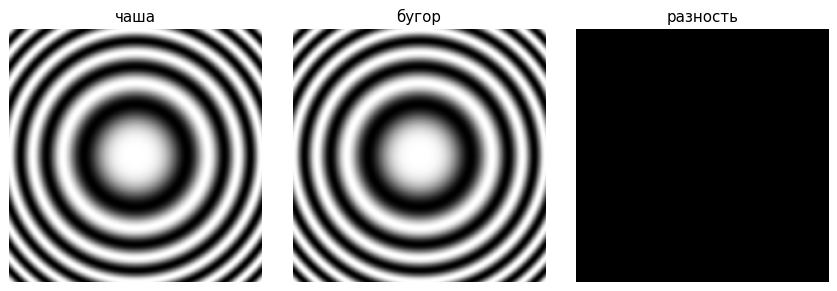

Наибольшая разность яркостей: 0.0


In [69]:
I_bowl = A + B * np.cos(+phi_bowl)     # чаша
I_bump = A + B * np.cos(-phi_bowl)     # бугор той же формы
show_row([I_bowl, I_bump, I_bowl - I_bump], ["чаша", "бугор", "разность"])
print("Наибольшая разность яркостей:", np.abs(I_bowl - I_bump).max())

**Что мы видим.** Картинки совпадают до последнего пикселя. По одному кадру яма и бугор неразличимы — поэтому старые методы (трассировка, Фурье) знак не измеряют, а *предполагают*.

> **Конец части I.** Хорошее место для остановки. Главное:
> - когерентные волны складываются как стрелки, интенсивность — квадрат суммы;
> - **I = I₁ + I₂ + 2√(I₁I₂)·cos φ = A + B·cos φ**, при равных пучках — от 0 до 4·I₀;
> - фаза определена «по кругу», а из одного кадра её не достать.

---
# Часть II. Фазовый сдвиг, когда сдвиги известны

## Глава 5. Двигаем опорное зеркало

Пьезопривод сдвигает эталон вдоль оси на крошечное расстояние. Опорный путь меняется на одну и ту же величину **во всех точках**, значит, ко всей фазе добавляется одно и то же число δ:

$$I_n = A + B\cos(\varphi + \delta_n)$$

Сдвиг зеркала на λ/8 даёт δ = 90° (путь туда-обратно — λ/4 — это четверть волны).

Снимем 4 кадра со сдвигами 0°, 90°, 180°, 270°.

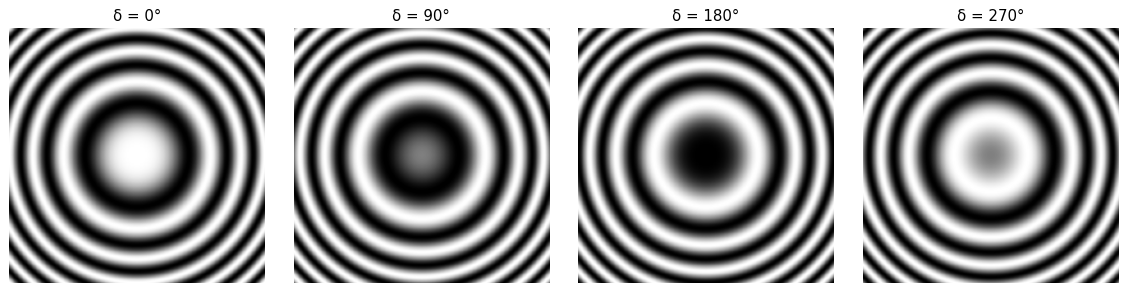

In [70]:
shifts = np.array([0, 90, 180, 270]) * deg
frames = np.array([A + B * np.cos(phi_bowl + d) for d in shifts])
show_row(frames, [f"δ = {d/deg:.0f}°" for d in shifts])

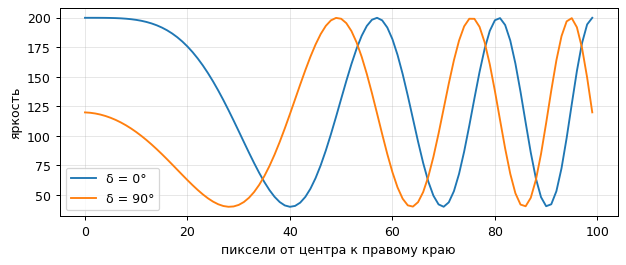

In [71]:
# Срез по горизонтали через центр: как ведут себя полосы при сдвиге.
row = frames.shape[1] // 2
plt.figure(figsize=(8, 3))
for f, d in zip(frames[:2], shifts[:2]):
    plt.plot(f[row, 100:], label=f"δ = {d/deg:.0f}°")
plt.xlabel("пиксели от центра к правому краю"); plt.ylabel("яркость")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Что мы видим.** При сдвиге кольца «бегут». На срезе максимумы второго кадра стоят ближе к центру: кольца **сжимаются к центру**.

А вот это главное: у **бугра** при том же сдвиге кольца бежали бы **наружу**. Направление движения зеркала мы знаем — значит, по направлению бега полос знак **измеряется**. В этом преимущество фазового сдвига перед одним кадром.

> **Проверь себя.** Замени в первой клетке главы `phi_bowl + d` на `-phi_bowl + d` (бугор) и посмотри на срез.
> <details><summary>ответ</summary>Максимумы сдвинутся в другую сторону — к краю.</details>

## Глава 6. Одна точка, четыре кадра → фаза

Возьмём **один пиксель**. Распишем его 4 яркости через формулы косинуса суммы:

| кадр | δ | I |
|---|---|---|
| 1 | 0° | A + B cos φ |
| 2 | 90° | A − B sin φ |
| 3 | 180° | A − B cos φ |
| 4 | 270° | A + B sin φ |

Вычтем попарно — фон A уходит:

- I₁ − I₃ = 2B cos φ
- I₄ − I₂ = 2B sin φ

Отношение даёт тангенс, и контраст B тоже сокращается:

$$\varphi = \operatorname{atan2}(I_4 - I_2,\; I_1 - I_3)$$

(`atan2(y, x)` — «угол точки (x, y)»: в отличие от простого арктангенса, он учитывает знаки и даёт угол во всём круге.)

In [72]:
phi_true = 50 * deg                 # <- задумаем фазу в точке
A1, B1 = 120, 80
I1, I2, I3, I4 = [A1 + B1 * np.cos(phi_true + d) for d in np.array([0, 90, 180, 270]) * deg]
print("яркости:", round(I1, 1), round(I2, 1), round(I3, 1), round(I4, 1))
print("найденная фаза:", np.arctan2(I4 - I2, I1 - I3) / deg, "градусов")

яркости: 171.4 58.7 68.6 181.3
найденная фаза: 49.999999999999986 градусов


Работает. Теперь сделаем то же самое **во всех пикселях сразу** — это одна строка numpy.

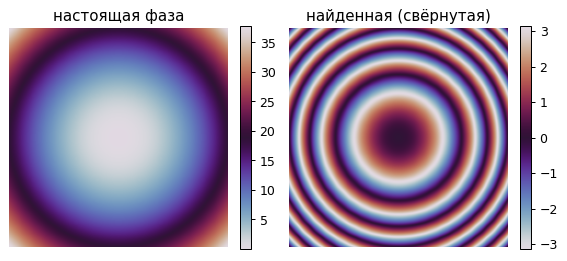

In [73]:
I1, I2, I3, I4 = frames
phi_wrapped = np.arctan2(I4 - I2, I1 - I3)
show_row([phi_bowl, phi_wrapped], ["настоящая фаза", "найденная (свёрнутая)"], cmap="twilight", colorbar=True)

**Что мы видим.** Справа — та же чаша, но «нарезанная» на кольца: значения только от −180° до +180° (−π…π). Это **свёрнутая фаза**: atan2 не знает, сколько полных оборотов уже было. Зато внутри каждого кольца фаза найдена точно, **в каждом пикселе**, без всякой трассировки.

## Глава 7. Развёртка: склеиваем обороты

Пройдём вдоль строки. Пока фаза меняется плавно, соседние пиксели отличаются на немного. Если вдруг значение прыгнуло на ~360° — это не обрыв детали, а atan2 «перескочил» через границу круга. Добавим или вычтем 360°, чтобы прыжка не было.

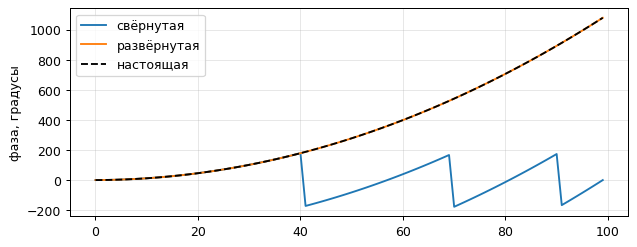

In [74]:
line = phi_wrapped[100, 100:]                 # от центра к правому краю
unwrapped = np.unwrap(line)                   # np.unwrap как раз убирает скачки на 2π

plt.figure(figsize=(8, 3))
plt.plot(line / deg, label="свёрнутая")
plt.plot(unwrapped / deg, label="развёрнутая")
plt.plot(phi_bowl[100, 100:] / deg, "k--", label="настоящая")
plt.ylabel("фаза, градусы"); plt.legend(); plt.grid(alpha=0.3); plt.show()

Для всей картинки самый простой способ: развернуть первый столбец, затем от него — каждую строку.

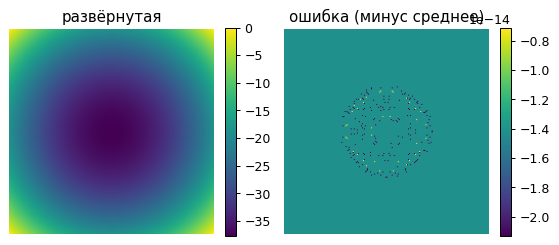

Ошибка после вычета константы: 2.1316282072803006e-14


In [75]:
def unwrap_2d_simple(p):
    out = p.copy()
    out[:, 0] = np.unwrap(out[:, 0])             # первый столбец сверху вниз
    for r in range(out.shape[0]):                # каждую строку слева направо от него
        out[r] = np.unwrap(out[r])
    return out

phi_unwrapped = unwrap_2d_simple(phi_wrapped)
diff = phi_unwrapped - phi_bowl
show_row([phi_unwrapped, diff - diff.mean()], ["развёрнутая", "ошибка (минус среднее)"], cmap="viridis", colorbar=True)
print("Ошибка после вычета константы:", np.abs(diff - diff.mean()).max())

**Что мы видим.** Фаза восстановлена с точностью до **константы** — а константа (общая высота детали) нам и не нужна.

В DigitQt развёртка умнее: она идёт сначала по самым надёжным точкам (где контраст выше) и обходит шум. Принцип тот же — склеивать соседей.

> **Конец главы 7.** Хорошее место для остановки. Мы прошли «классический» фазовый сдвиг: 4 кадра → atan2 → развёртка.

## Глава 8. Сдвиги любые, но известные: подгонка (МНК)

Формула из главы 6 работает только для сдвигов ровно 0/90/180/270°. А если пьезо дал 0°, 72°, 198°, 266°, 36° и мы это знаем?

Хитрость: раскроем косинус суммы.

$$I_n = A + B\cos(\varphi+\delta_n) = A + \underbrace{B\cos\varphi}_{c}\cdot\cos\delta_n - \underbrace{B\sin\varphi}_{s}\cdot\sin\delta_n$$

Если сдвиги δ_n **известны**, то `cos δ_n` и `sin δ_n` — просто числа. Неизвестные — `A`, `c`, `s`, и они входят **линейно**. Это как провести прямую через точки — задача **метода наименьших квадратов** (МНК).

Сначала вспомним МНК на прямой.

нашли k = 2.01, b = 3.32   (задумано 2 и 3)


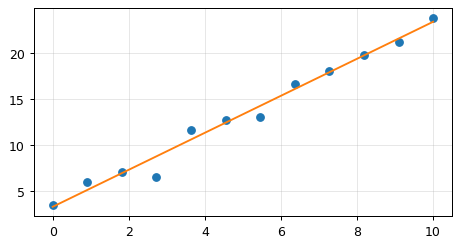

In [76]:
rng = np.random.default_rng(1)
x = np.linspace(0, 10, 12)
y = 2.0 * x + 3.0 + rng.normal(0, 1.5, x.size)      # «измерения»: прямая 2x+3 плюс шум

M = np.column_stack([x, np.ones_like(x)])          # каждая строка: [x, 1] — коэффициенты при неизвестных (k, b)
k, b = np.linalg.lstsq(M, y, rcond=None)[0]        # МНК: подобрать k, b, чтобы сумма квадратов ошибок была минимальна
print(f"нашли k = {k:.2f}, b = {b:.2f}   (задумано 2 и 3)")

plt.figure(figsize=(6, 3)); plt.plot(x, y, "o"); plt.plot(x, k * x + b)
plt.grid(alpha=0.3); plt.show()

С косинусом то же самое, только строка матрицы — `[1, cos δ, −sin δ]`, а неизвестные — `(A, c, s)`. После подгонки фаза — угол точки `(c, s)`: **φ = atan2(s, c)**.

A = 120.0, B = 80.0, φ = 50.00°


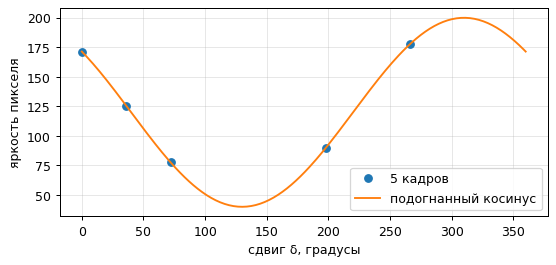

In [77]:
shifts5 = np.array([0, 72, 198, 266.4, 36]) * deg     # сдвиги из статьи Парпина–Серегина (рис. 4)
phi_true = 50 * deg
I_px = A1 + B1 * np.cos(phi_true + shifts5)           # 5 яркостей одного пикселя

M = np.column_stack([np.ones(5), np.cos(shifts5), -np.sin(shifts5)])
a, c, s = np.linalg.lstsq(M, I_px, rcond=None)[0]
print(f"A = {a:.1f}, B = {np.hypot(c, s):.1f}, φ = {np.arctan2(s, c)/deg:.2f}°")

d = np.linspace(0, 2 * np.pi, 200)
plt.figure(figsize=(7, 3))
plt.plot(shifts5 / deg, I_px, "o", label="5 кадров")
plt.plot(d / deg, a + c * np.cos(d) - s * np.sin(d), label="подогнанный косинус")
plt.xlabel("сдвиг δ, градусы"); plt.ylabel("яркость пикселя"); plt.legend(); plt.grid(alpha=0.3); plt.show()

**Что мы видим.** Пять точек на графике «яркость от сдвига» лежат на одном косинусе. Его положение по горизонтали и есть фаза пикселя.

Оформим это функцией для всей картинки сразу — она пригодится до конца тетрадки. **Это шаг 1 всех алгоритмов дальше** (в DigitQt — `computePhase`).

In [78]:
def phase_from_shifts(frames, shifts):
    # ШАГ 1. Сдвиги известны -> в каждом пикселе подгоняем A + c*cos(δ) - s*sin(δ) по кадрам.
    n = len(frames)
    M = np.column_stack([np.ones(n), np.cos(shifts), -np.sin(shifts)])     # n x 3, одна на все пиксели
    I = frames.reshape(n, -1)                                                # n x (все пиксели)
    a, c, s = np.linalg.lstsq(M, I, rcond=None)[0]                           # МНК сразу для всех пикселей
    return np.arctan2(s, c).reshape(frames.shape[1:])

frames5 = np.array([A + B * np.cos(phi_bowl + d) for d in shifts5])
phi5 = phase_from_shifts(frames5, shifts5)
err = wrap(phi5 - phi_bowl)
print("Ошибка фазы с ВЕРНЫМИ сдвигами:", np.abs(err).max() / deg, "градусов")

Ошибка фазы с ВЕРНЫМИ сдвигами: 1.614552438224558e-13 градусов


## Глава 9. Что будет, если считать с неверными сдвигами

На практике пьезо не откалиброван, а стенд вибрирует. Мы *думаем*, что сдвиги 0/90/180/270/360°, а на деле — 0/72/198/266/36°. Посчитаем фазу с номинальными сдвигами.

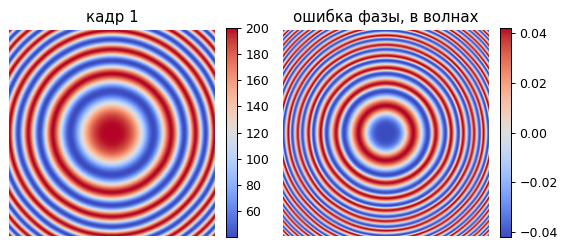

СКО ошибки: 0.0298 волны


In [79]:
nominal = np.array([0, 90, 180, 270, 360]) * deg
phi_bad = phase_from_shifts(frames5, nominal)
err_bad = wrap(phi_bad - phi_bowl)
err_bad -= err_bad.mean()
show_row([frames5[0], err_bad / (2 * np.pi)], ["кадр 1", "ошибка фазы, в волнах"], cmap="coolwarm", colorbar=True)
print(f"СКО ошибки: {np.std(err_bad) / (2*np.pi):.4f} волны")

**Что мы видим.** Ошибка — не шум, а **рябь, повторяющая полосы** (удвоенной частоты). Около 0,03 волны — для оптики это много.

Это главная беда фазового сдвига на реальном стенде: формулы верны, а **сдвиги, которые мы в них подставляем, — нет**.

> **Проверь себя.** Почему ошибка повторяет рисунок полос, а не случайна?
> <details><summary>ответ</summary>Ошибка зависит от того, где на круге находится φ: при одних фазах неверные сдвиги «тянут» результат в одну сторону, при других — в другую. Фаза меняется вместе с полосами — значит, и ошибка.</details>

---
# Часть III. Сдвиги неизвестны

## Глава 10. Обратная задача: фаза известна → находим сдвиг кадра

Посмотрим на формулу ещё раз и заметим **симметрию**:

$$I = A + B\cos(\varphi + \delta)$$

φ и δ входят в неё **одинаково**. В главе 8 мы знали δ и для каждого **пикселя** подгоняли косинус по кадрам. А теперь наоборот: пусть фаза φ **известна** (во всех пикселях), а сдвиг δ одного **кадра** — нет. Тогда для этого кадра:

$$I(\text{пиксель}) = A + \underbrace{B\cos\delta}_{c}\cdot\cos\varphi(\text{пиксель}) - \underbrace{B\sin\delta}_{s}\cdot\sin\varphi(\text{пиксель})$$

Та же самая подгонка, только «точки» — это **пиксели** кадра, а по горизонтали — их фаза.

найденный сдвиг кадра: 72.00°  (на деле 72°)


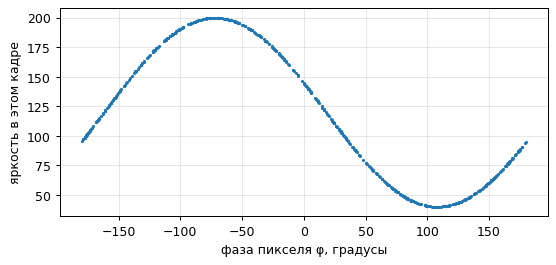

In [80]:
frame = frames5[1]                       # кадр со сдвигом 72° — делаем вид, что сдвиг не знаем
p = phi_bowl.ravel()                     # известная фаза каждого пикселя
I = frame.ravel()

M = np.column_stack([np.ones(p.size), np.cos(p), -np.sin(p)])
a, c, s = np.linalg.lstsq(M, I, rcond=None)[0]
print(f"найденный сдвиг кадра: {np.arctan2(s, c)/deg:.2f}°  (на деле 72°)")

pick = np.random.default_rng(0).choice(p.size, 600, replace=False)
plt.figure(figsize=(7, 3))
plt.plot(wrap(p[pick]) / deg, I[pick], ".", ms=3)
plt.xlabel("фаза пикселя φ, градусы"); plt.ylabel("яркость в этом кадре"); plt.grid(alpha=0.3); plt.show()

**Что мы видим.** Облако точек «яркость от фазы пикселя» — косинус, сдвинутый ровно на сдвиг кадра.

**Важное условие.** Чтобы косинус по облаку подгонялся надёжно, фазы пикселей должны **покрывать весь круг** — значит, в кадре должна быть хотя бы одна полоса. Если полос нет, все точки окажутся в одном месте круга, и подгонять нечего. Запомним — это вернётся в главе 12.

Тоже оформим функцией. **Это шаг 2.**

In [81]:
def shifts_from_phase(frames, phi, mask=None):
    # ШАГ 2. Фаза известна -> для каждого кадра подгоняем A + c*cos(φ) - s*sin(φ) по пикселям.
    p = phi[mask] if mask is not None else phi.ravel()
    M = np.column_stack([np.ones(p.size), np.cos(p), -np.sin(p)])
    found = []
    for f in frames:
        I = f[mask] if mask is not None else f.ravel()
        a, c, s = np.linalg.lstsq(M, I, rcond=None)[0]
        found.append(np.arctan2(s, c))
    found = np.array(found)
    return np.mod(found - found[0], 2 * np.pi)       # отсчёт от первого кадра: его сдвиг = 0

print(np.round(shifts_from_phase(frames5, phi_bowl) / deg, 2))

[  0.   72.  198.  266.4  36. ]


## Глава 11. «Качели»: не знаем ни фазу, ни сдвиги

Теперь самое интересное. Реальная ситуация: у нас **только кадры**. Ни фаза, ни сдвиги не известны.

Но у нас есть два умения:

- **шаг 1**: по сдвигам → фаза (глава 8);
- **шаг 2**: по фазе → сдвиги (глава 10).

Идея: начнём с **номинальных** сдвигов (0/90/180/…). Они неверны, но не совсем. Посчитаем по ним фазу — она будет с рябью, но похожа на правду. По этой фазе уточним сдвиги — они станут ближе к настоящим. По ним — фаза точнее. И так далее, туда-сюда, как на качелях, пока сдвиги не перестанут меняться.

Это алгоритм **AIA** (Wang–Han, 2004) и, по сути, алгоритм из статьи **Парпина–Серегина (2012)**. В DigitQt — `solveWithUnknownShifts`.

In [82]:
def swing(frames, start_shifts, max_iter=100, mask=None, show=True):
    # «Качели»: шаг 1 и шаг 2 по очереди, пока сдвиги не перестанут меняться.
    shifts = np.array(start_shifts, dtype=float)
    history = [shifts.copy()]
    for it in range(1, max_iter + 1):
        phi = phase_from_shifts(frames, shifts)            # шаг 1
        new = shifts_from_phase(frames, phi, mask)         # шаг 2
        change = np.abs(wrap(new - shifts)).max()          # насколько сдвинулись за круг
        shifts = new
        history.append(shifts.copy())
        if show and (it <= 5 or it % 10 == 0):
            print(f"итерация {it:3d}: сдвиги {np.round(shifts / deg, 2)}, изменение {change / deg:.5f}°")
        if change < 1e-5 * deg:
            if show:
                print(f"итерация {it:3d}: сдвиги {np.round(shifts / deg, 2)} — сошлось")
            break
    return phase_from_shifts(frames, shifts), shifts, np.array(history)

phi_s, shifts_s, hist = swing(frames5, nominal)

итерация   1: сдвиги [  0.    84.96 197.99 281.12  39.09], изменение 39.09394°
итерация   2: сдвиги [  0.    77.85 198.41 272.87  37.99], изменение 8.25220°
итерация   3: сдвиги [  0.    74.58 198.24 269.23  36.95], изменение 3.63367°
итерация   4: сдвиги [  0.    73.13 198.12 267.64  36.43], изменение 1.58855°
итерация   5: сдвиги [  0.    72.5  198.05 266.95  36.19], изменение 0.69676°
итерация  10: сдвиги [  0.    72.01 198.   266.41  36.  ], изменение 0.01156°
итерация  19: сдвиги [  0.   72.  198.  266.4  36. ] — сошлось


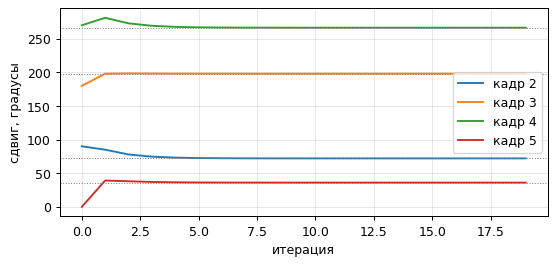

СКО ошибки фазы: было 0.0298 волны (номинальные сдвиги), стало 0.000000 волны


In [83]:
plt.figure(figsize=(7, 3))
for k in range(1, hist.shape[1]):
    plt.plot(np.mod(hist[:, k], 2 * np.pi) / deg, label=f"кадр {k+1}")      # по модулю 360°: 360° = 0°
for v in [72, 198, 266.4, 36]:
    plt.axhline(v, color="gray", ls=":", lw=0.8)
plt.xlabel("итерация"); plt.ylabel("сдвиг, градусы"); plt.legend(); plt.grid(alpha=0.3); plt.show()

err_s = wrap(phi_s - phi_bowl); err_s -= err_s.mean()
print(f"СКО ошибки фазы: было {np.std(err_bad)/(2*np.pi):.4f} волны (номинальные сдвиги), "
      f"стало {np.std(err_s)/(2*np.pi):.6f} волны")

**Что мы видим.** За несколько итераций сдвиги «съехали» с номинальных 90/180/270/360° на настоящие 72/198/266/36° (пунктир). Ошибка фазы упала в сотни раз — до уровня, которого достигли бы с заранее известными верными сдвигами.

Ни одного нового измерения — только кадры и терпение.

> **Конец главы 11.** Главное место в тетрадке. Если «качели» понятны, всё остальное — их вариации.

## Глава 12. Ловушки «качелей»

### 12а. Мало полос

Вспомним условие из главы 10: фазы пикселей должны покрывать круг. Есть и второе, скрытое допущение шага 2: подгоняя один косинус по **всем пикселям кадра**, мы считаем, что фон A и контраст B **одинаковы по всему кадру**. В жизни это не так: лазерный пучок ярче в центре и темнее к краю.

Сделаем такой пучок, добавим шум камеры и сравним деталь с 0,15 полосы и с 6 полосами.

на деле:        [  0.   72.  198.  266.4  36. ]
0.15 полосы:   [  0.    2.6 347.6 355.7   1.1]
   6 полосы:   [  0.   75.4 203.8 270.8  37.1]


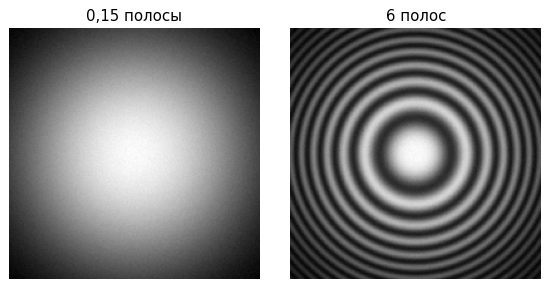

In [84]:
rng = np.random.default_rng(0)
beam = np.exp(-(X**2 + Y**2))                         # пучок: в центре ярко, к краю темнее

def camera_frames(phi, shifts):
    # Кадры «как с камеры»: неравномерный пучок, шум ±2 уровня, округление до целых.
    return np.array([np.round(beam * (A + B * np.cos(phi + d)) + rng.normal(0, 2, phi.shape))
                     for d in shifts])

print("на деле:       ", np.round(shifts5 / deg, 1))
for fringes in [0.15, 6]:
    frames_c = camera_frames(2 * np.pi * fringes * (X**2 + Y**2), shifts5)
    _, found, _ = swing(frames_c, nominal, show=False)
    print(f"{fringes:4} полосы:  ", np.round(found / deg, 1))
show_row([camera_frames(2 * np.pi * 0.15 * (X**2 + Y**2), shifts5)[0],
          camera_frames(2 * np.pi * 6 * (X**2 + Y**2), shifts5)[0]], ["0,15 полосы", "6 полос"])

**Что мы видим.**

- При **0,15 полосы** сдвиги найдены совсем неверно. Почти вся разница яркостей по кадру — это пучок, а не полосы, и шаг 2 принимает пучок за полосу. Это ровно серии `big` и `i1` Серегина.
- При **6 полосах** — близко к правде, но ошибка в несколько градусов остаётся: допущение «A и B одинаковы по кадру» всё-таки нарушено. (Её убирает алгоритм GIA из главы 16: там фон и контраст оцениваются в маленьком окне вокруг каждой точки.)

**Вывод для стенда:** для расчёта сдвигов нужна **несущая** — наклон эталона, дающий несколько полос на поле, — и подсветка как можно ровнее.

### 12б. Зеркальное решение

Помните `cos φ = cos(−φ)`? У «качелей» та же неоднозначность: если **одновременно** поменять знак и у фазы, и у всех сдвигов, кадры не изменятся.

In [85]:
d_true = np.array([0, 10, 110, 30]) * deg            # пример рис. 8 из статьи 2012 г.
frames_a = np.array([A + B * np.cos(+phi_bowl + d) for d in +d_true])   # чаша, сдвиги +
frames_b = np.array([A + B * np.cos(-phi_bowl + d) for d in -d_true])   # бугор, сдвиги −
print("Наибольшая разность кадров:", np.abs(frames_a - frames_b).max())

_, found, _ = swing(frames_a, np.array([0, 90, 180, 270]) * deg, show=False)
print("Настоящие сдвиги:", np.round(np.mod(d_true, 2*np.pi) / deg, 1))
print("Найденные:       ", np.round(found / deg, 1), " <- это минус настоящие (360-10=350, ...)")

Наибольшая разность кадров: 0.0
Настоящие сдвиги: [  0.  10. 110.  30.]
Найденные:        [  0. 350. 250. 330.]  <- это минус настоящие (360-10=350, ...)


**Что мы видим.** Две разные ситуации (чаша со сдвигами вперёд, бугор со сдвигами назад) дают **одни и те же** кадры. Какое решение найдут «качели», зависит от начальных сдвигов. Здесь настоящие сдвиги 0/10/110/30° дальше от номинальных 0/90/180/270°, чем зеркальные 0/350/250/330°, — и алгоритм пришёл к зеркальному. **Карта перевёрнута, и по кадрам этого не узнать.**

Поэтому знак задаёт только знание о том, **куда реально двигался пьезо** (номинальный шаг). Это открытый вопрос к Серегину: как его программа гарантирует знак при сильных вибрациях.

---
# Часть IV. Сдвиг с наклоном

## Глава 13. Откуда берётся наклон и чем он вредит

До сих пор мы считали, что пьезо сдвигает зеркало **строго вдоль оси**, и сдвиг одинаков во всём кадре. Но если зеркало при этом ещё и **чуть поворачивается** (вибрация, неравный ход нескольких пьезостолбиков), то путь меняется по-разному в разных точках: с одной стороны больше, с другой меньше. Сдвиг кадра становится **плоскостью**:

$$\delta_n(x, y) = \underbrace{\delta_n}_{\text{сдвиг в центре}} + \underbrace{k_{x,n}\,x + k_{y,n}\,y}_{\text{наклон}}$$

Сколько это на нашем стенде? Поворот зеркала на угол α меняет путь на `2·α·D` поперёк апертуры D.

In [86]:
alpha = 5e-6      # поворот зеркала, радианы (5 микрорадиан — очень мало)
D = 0.100         # апертура, метры
for name, lam in [("видимый, 0.63 мкм", 0.633e-6), ("наш ИК, 10.6 мкм", 10.6e-6)]:
    waves = 2 * alpha * D / lam
    print(f"{name:20s}: разность сдвига от края до края {waves:.2f} волны = {waves*360:.0f}°")

видимый, 0.63 мкм   : разность сдвига от края до края 1.58 волны = 569°
наш ИК, 10.6 мкм    : разность сдвига от края до края 0.09 волны = 34°


Длинная волна прощает вибрации в 17 раз — хороший аргумент за ИК-стенд. Но 34° — всё равно ощутимо.

Сделаем серию кадров **с наклоном** и посмотрим, что сделают с ней обычные «качели».

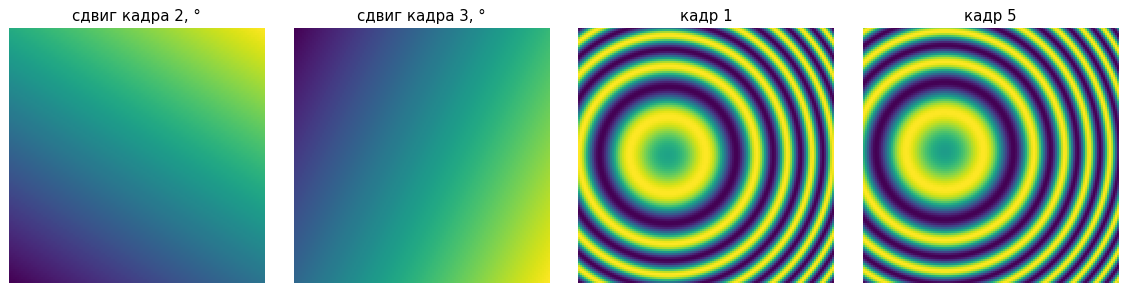

In [87]:
X, Y = grid(128)
phi_t = 2 * np.pi * (2.5 * (X**2 + Y**2) + 1.5 * X)      # чаша + несущая: полос достаточно
shifts_t = np.array([0, 72, 198, 266.4, 36]) * deg
tilt_x = np.array([0, 0.5, 1.0, 1.5, 2.0])               # наклон по x, рад от центра до края
tilt_y = np.array([0, -0.8, 0.5, -0.3, 1.0])             # наклон по y

shift_maps = np.array([d + kx * X + ky * Y for d, kx, ky in zip(shifts_t, tilt_x, tilt_y)])
frames_t = np.array([A + B * np.cos(phi_t + m) for m in shift_maps])

show_row(list(shift_maps[1:3] / deg) + [frames_t[0], frames_t[4]],
         ["сдвиг кадра 2, °", "сдвиг кадра 3, °", "кадр 1", "кадр 5"], cmap="viridis")

Качели нашли сдвиги: [  0.   81.6 199.6 272.8  38.9]


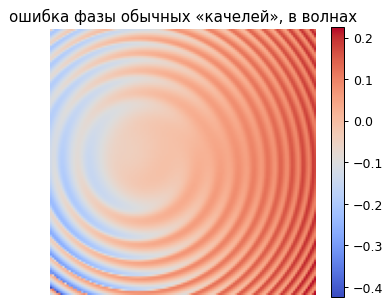

СКО ошибки: 0.0962 волны


In [88]:
phi_ts, sh_ts, _ = swing(frames_t, nominal, show=False)
err_ts = wrap(phi_ts - phi_t); err_ts -= err_ts.mean()
print("Качели нашли сдвиги:", np.round(sh_ts / deg, 1))
show_row([err_ts / (2 * np.pi)], ["ошибка фазы обычных «качелей», в волнах"], cmap="coolwarm", size=4, colorbar=True)
print(f"СКО ошибки: {np.std(err_ts)/(2*np.pi):.4f} волны")

**Что мы видим.** «Качели» сошлись к *каким-то* сдвигам, но карта испорчена: модель «одно число на кадр» не может описать плоскость.

Как это заметить на **реальных** кадрах, где правды мы не знаем? Двумя способами — они встроены в DigitQt:

1. **Невязка.** Пересчитаем кадры по найденным фазе и сдвигам и сравним с настоящими. Если модель верна — разница на уровне шума.
2. **Половины.** Найдём сдвиги отдельно по левой и по правой половине кадра. Если сдвиг один на весь кадр — ответы совпадут. При наклоне — разойдутся.

In [89]:
def residual(frames, phi, shift_maps):
    # Насколько кадры отличаются от модели A + B*cos(φ + сдвиг). Сдвиги — числа или карты.
    out = []
    for f, m in zip(frames, shift_maps):
        c = np.cos(phi + m)
        M = np.column_stack([np.ones(c.size), c.ravel()])       # подгоняем A и B кадра
        ab = np.linalg.lstsq(M, f.ravel(), rcond=None)[0]
        out.append(f.ravel() - M @ ab)
    return np.sqrt(np.mean(np.square(out)))

left, right = X < 0, X >= 0
print(f"невязка: {residual(frames_t, phi_ts, sh_ts):.2f} уровня яркости (у идеальных кадров ~0)")
print("сдвиги по левой половине: ", np.round(shifts_from_phase(frames_t, phi_ts, left) / deg, 1))
print("сдвиги по правой половине:", np.round(shifts_from_phase(frames_t, phi_ts, right) / deg, 1))

невязка: 26.92 уровня яркости (у идеальных кадров ~0)
сдвиги по левой половине:  [  0.   66.5 165.6 231.1 335.5]
сдвиги по правой половине: [  0.   84.5 222.  307.3  82.9]


## Глава 14. Метод Liu: столбец за столбцом

(Q. Liu и др., *Optics Express*, 2013 — статья в этой же папке. В DigitQt — `solveWithTiltShifts`.)

Нам нужно в шаге 2 найти не одно число на кадр, а плоскость: `δ + kx·x + ky·y`. Хитрость Liu:

**Посмотри на один столбец кадра** (x фиксирован). Внутри столбца `kx·x` — просто константа! Значит, для одного столбца задача — **ровно та же, что в главе 10**: найти один сдвиг по пикселям столбца.

Сделаем это для каждого столбца → получим «сдвиг столбца» как функцию x → это должна быть **прямая**, её наклон и есть `kx`.

Сначала — на настоящей фазе, чтобы увидеть саму идею.

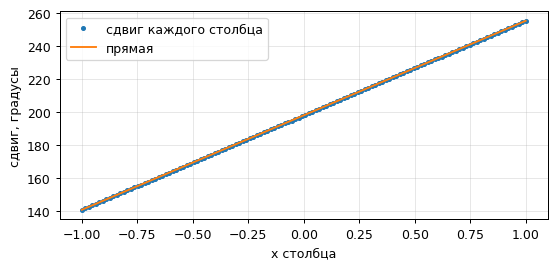

наклон по x: найдено 1.0000, на деле 1.0000;  сдвиг в центре: 198.00° (на деле 198.0°)


In [90]:
def line_shifts(frame, known_phase, axis, mask=None):
    # Сдвиг каждого столбца (axis=0) или строки (axis=1): та же подгонка, что в главе 10.
    # Возвращает сдвиги линий и число годных точек в каждой линии.
    if axis == 1:                                     # строки = столбцы транспонированной картинки
        frame, known_phase = frame.T, known_phase.T
        mask = mask.T if mask is not None else None
    n_lines = frame.shape[1]
    result, weight = np.zeros(n_lines), np.zeros(n_lines)
    for j in range(n_lines):
        sel = mask[:, j] if mask is not None else slice(None)
        p, I = known_phase[sel, j], frame[sel, j]
        if p.size < 10:
            continue                                  # слишком мало точек в линии — пропускаем
        M = np.column_stack([np.ones(p.size), np.cos(p), -np.sin(p)])
        a, c, s = np.linalg.lstsq(M, I, rcond=None)[0]
        result[j], weight[j] = np.arctan2(s, c), p.size
    return result, weight

def fit_line(values, weight, coord):
    # Развернуть сдвиги линий (убрать скачки на 360°) и провести через них прямую.
    ok = weight > 0
    u = np.unwrap(values[ok])
    k, b = np.polyfit(coord[ok], u, 1, w=np.sqrt(weight[ok]))
    return k, wrap(b)

xs = np.linspace(-1, 1, frames_t.shape[2])
n = 2                                                  # кадр 3
known = phi_t + tilt_y[n] * Y + 0                      # фаза + известная y-часть сдвига
col, w = line_shifts(frames_t[n], known, axis=0)
kx, dx = fit_line(col, w, xs)

plt.figure(figsize=(7, 3))
u = np.unwrap(col)
line = kx * xs + dx
line += 2 * np.pi * np.round(np.mean(u - line) / (2 * np.pi))   # та же прямая, но на том же «обороте», что и точки
plt.plot(xs, u / deg, ".", label="сдвиг каждого столбца")
plt.plot(xs, line / deg, label="прямая")
plt.xlabel("x столбца"); plt.ylabel("сдвиг, градусы"); plt.legend(); plt.grid(alpha=0.3); plt.show()
print(f"наклон по x: найдено {kx:.4f}, на деле {tilt_x[n]:.4f};  сдвиг в центре: {np.mod(dx, 2*np.pi)/deg:.2f}° (на деле {shifts_t[n]/deg:.1f}°)")

**Что мы видим.** Сдвиги столбцов легли на прямую, и её наклон совпал с настоящим.

То же самое по **строкам** даёт наклон по y. А раз настоящая фаза нам неизвестна — снова «качели», только теперь из трёх шагов:

1. **фаза** при известных плоскостях сдвига (как глава 8, но у каждого пикселя свой сдвиг);
2. **столбцы** → наклон по x;
3. **строки** → наклон по y;

…и по кругу. Первый кадр — точка отсчёта, у него сдвиг и наклоны нулевые.

In [91]:
def phase_from_shift_maps(frames, shift_maps):
    # ШАГ 1 с наклоном: в каждом пикселе свои сдвиги -> своя матрица 3x3. Решаем все сразу.
    rows = [np.ones_like(shift_maps), np.cos(shift_maps), -np.sin(shift_maps)]
    M = np.stack([np.stack([(ri * rj).sum(0) for rj in rows], -1) for ri in rows], -2)   # H x W x 3 x 3
    r = np.stack([(ri * frames).sum(0) for ri in rows], -1)                               # H x W x 3
    a, c, s = np.moveaxis(np.linalg.solve(M, r[..., None])[..., 0], -1, 0)
    return np.arctan2(s, c)

def liu(frames, start_shifts, max_iter=100, mask=None, show=True):
    nf, H, W = frames.shape
    X, Y = np.meshgrid(np.linspace(-1, 1, W), np.linspace(-1, 1, H))
    xs, ys = X[0], Y[:, 0]
    dx = np.array(start_shifts, float)              # x-часть сдвига (в центре)
    dy, kx, ky = np.zeros(nf), np.zeros(nf), np.zeros(nf)
    maps = lambda: (dx + dy)[:, None, None] + kx[:, None, None] * X + ky[:, None, None] * Y
    for it in range(1, max_iter + 1):
        old = np.concatenate([dx + dy, kx, ky])
        phi = phase_from_shift_maps(frames, maps())                       # шаг 1
        for i in range(1, nf):                                            # шаг 2: столбцы
            col, w = line_shifts(frames[i], phi + ky[i] * Y + dy[i], 0, mask)
            kx[i], dx[i] = fit_line(col, w, xs)
        phi = phase_from_shift_maps(frames, maps())
        for i in range(1, nf):                                            # шаг 3: строки
            row, w = line_shifts(frames[i], phi + kx[i] * X + dx[i], 1, mask)
            ky[i], dy[i] = fit_line(row, w, ys)
        change = np.abs(wrap(np.concatenate([dx + dy, kx, ky]) - old)).max()
        if show and (it <= 3 or it % 10 == 0):
            print(f"итерация {it:3d}: наклоны x {np.round(kx, 3)}, изменение {change:.1e}")
        if change < 1e-6:
            if show:
                print(f"итерация {it:3d}: сошлось")
            break
    return phase_from_shift_maps(frames, maps()), np.mod(dx + dy, 2 * np.pi), kx, ky, maps()

phi_l, sh_l, kx_l, ky_l, maps_l = liu(frames_t, nominal)

итерация   1: наклоны x [ 0.    -0.441  0.009  0.527  0.855], изменение 1.0e+00
итерация   2: наклоны x [ 0.    -0.404  0.225  0.628  1.151], изменение 3.0e-01
итерация   3: наклоны x [ 0.    -0.277  0.346  0.773  1.289], изменение 1.5e-01
итерация  10: наклоны x [0.    0.266 0.791 1.289 1.781], изменение 4.4e-02
итерация  20: наклоны x [0.    0.458 0.96  1.461 1.959], изменение 7.9e-03
итерация  30: наклоны x [0.    0.492 0.993 1.493 1.992], изменение 1.4e-03
итерация  40: наклоны x [0.    0.499 0.999 1.499 1.999], изменение 2.6e-04
итерация  50: наклоны x [0.  0.5 1.  1.5 2. ], изменение 4.8e-05
итерация  60: наклоны x [0.  0.5 1.  1.5 2. ], изменение 8.9e-06
итерация  70: наклоны x [0.  0.5 1.  1.5 2. ], изменение 1.6e-06
итерация  73: сошлось


сдвиги:      найдено [  0.   72.  198.  266.4  36. ]  на деле [  0.   72.  198.  266.4  36. ]
наклоны по x: найдено [0.  0.5 1.  1.5 2. ]  на деле [0.  0.5 1.  1.5 2. ]
наклоны по y: найдено [ 0.  -0.8  0.5 -0.3  1. ]  на деле [ 0.  -0.8  0.5 -0.3  1. ]
невязка: 0.000 уровня (было 26.9)


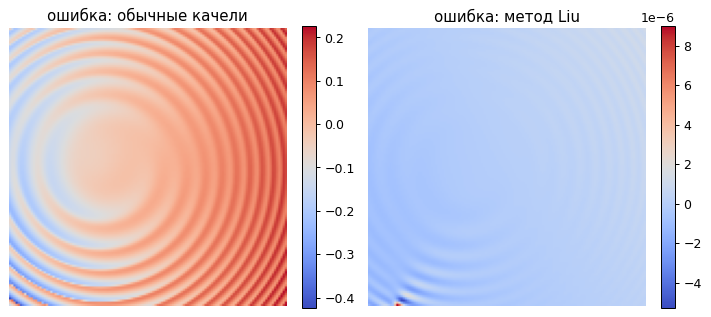

In [92]:
err_l = wrap(phi_l - phi_t); err_l -= err_l.mean()
print("сдвиги:      найдено", np.round(sh_l / deg, 2), " на деле", np.round(shifts_t / deg, 1))
print("наклоны по x: найдено", np.round(kx_l, 3), " на деле", tilt_x)
print("наклоны по y: найдено", np.round(ky_l, 3), " на деле", tilt_y)
print(f"невязка: {residual(frames_t, phi_l, maps_l):.3f} уровня (было {residual(frames_t, phi_ts, sh_ts):.1f})")
show_row([err_ts / (2*np.pi), err_l / (2*np.pi)], ["ошибка: обычные качели", "ошибка: метод Liu"],
         cmap="coolwarm", size=4, colorbar=True)

**Что мы видим.** Метод Liu нашёл и сдвиги, и наклоны каждого кадра; ошибка фазы исчезла (обрати внимание на шкалы), невязка упала до нуля.

Цена — то же условие, что в главе 12, только строже: полоса нужна **в каждом столбце и в каждой строке**, иначе сдвиг линии не определить.

## Глава 15. Настоящие кадры Серегина: серия Tilt-A

Возьмём серию `Tilt-A` из `notes/IDF`. Картинка круглая, вне круга темно — поэтому сдвиги будем искать только по точкам, где полосы есть: где яркость по кадрам меняется заметно («размах», как в DigitQt). Для скорости уменьшим кадры вдвое.

In [93]:
from PIL import Image

idf = Path("../IDF")
if not (idf / "Tilt-A_00.bmp").exists():
    idf = Path(r"C:\Ilya\dev\cpp\qt\digit-qt\notes\IDF")
real = np.array([np.asarray(Image.open(idf / f"Tilt-A_0{i}.bmp").convert("L"), float)[::2, ::2]
                 for i in range(5)])
span = real.max(0) - real.min(0)
mask = span > 0.3 * np.percentile(span, 99)               # точки с полосами
show_row([real[0], real[2], mask], ["Tilt-A, кадр 1", "кадр 3", "где ищем сдвиги"])

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Ilya\\dev\\cpp\\qt\\digit-qt\\notes\\IDF\\Tilt-A_00.bmp'

In [ ]:
phi_r1, sh_r1, _ = swing(real, nominal, mask=mask, show=False)
print("обычные качели:   сдвиги", np.round(sh_r1 / deg, 1),
      f" невязка {residual(real[:, mask], phi_r1[mask], sh_r1):.2f}")

phi_r2, sh_r2, kx_r, ky_r, maps_r = liu(real, nominal, mask=mask, show=False)
print("метод Liu:        сдвиги", np.round(sh_r2 / deg, 1),
      f" невязка {residual(real[:, mask], phi_r2[mask], maps_r[:, mask]):.2f}")
print("наклоны, волн на ширину кадра: x", np.round(kx_r * 2 / (2*np.pi), 2), " y", np.round(ky_r * 2 / (2*np.pi), 2))

diff_r = wrap(phi_r1 - phi_r2)
diff_r -= np.nanmean(np.where(mask, diff_r, np.nan))
show_row([np.where(mask, phi_r2, np.nan), np.where(mask, diff_r / (2 * np.pi), np.nan)],
         ["фаза: метод Liu (свёрнутая)", "разница методов, в волнах"], cmap="coolwarm", size=4, colorbar=True)

**Что мы видим.** Обычные «качели» дают невязку около 24 уровней яркости — модель не описывает кадры. Метод Liu — около четверти уровня (это уже округление яркости до целых): кадры объяснены полностью, найдены наклоны до ~0,4 волны на ширину кадра. Справа — разница фаз двух методов: это ошибка, которую обычные «качели» вносят из-за наклона. Она повторяет полосы и растёт к краям — там наклон сильнее всего сдвигает кадры.

Это те же числа, что даёт DigitQt с флажком «Compensate tilt between frames».

---
## Глава 16. Итог: карта понятий

```
I = A + B·cos(φ + δ)          ← всё начинается здесь (глава 2)
 │
 ├─ один кадр: 3 неизвестных, знак не виден (гл. 4)
 │
 ├─ сдвиги δ ИЗВЕСТНЫ  → шаг 1: подгонка в каждом пикселе → φ (гл. 6, 8)
 │      └─ неверные δ → рябь по полосам (гл. 9)
 │
 ├─ сдвиги НЕИЗВЕСТНЫ → симметрия φ ↔ δ → шаг 2: подгонка по пикселям кадра (гл. 10)
 │      └─ «качели»: шаг 1 ↔ шаг 2 (гл. 11)
 │            ловушки: мало полос, зеркальный знак (гл. 12)
 │
 └─ сдвиг С НАКЛОНОМ δ + kx·x + ky·y (гл. 13)
        └─ Liu: столбцы → kx, строки → ky, «качели» из 3 шагов (гл. 14, 15)
```

**Где это в DigitQt** (`src/core/psi/PhaseShifting.cpp`):

| в тетрадке | в коде |
|---|---|
| `phase_from_shifts` (шаг 1) | `computePhase`, `CosineFit` |
| `shifts_from_phase` (шаг 2) | `estimateShifts` |
| `swing` («качели») | `solveWithUnknownShifts` |
| `mask` по размаху | `selectShiftEstimationPoints` |
| невязка, половины | `PsiResult::Diagnostics` |
| `phase_from_shift_maps` | `computePhaseTilted` |
| `liu` | `solveWithTiltShifts` |

**Что дальше (из остальных статей папки), одной строкой каждое:**

- **GIA** (Chen–Kemao, 2021): та же идея «качелей», но в модель добавлены *гармоники* (несинусоидальные полосы от пересвета камеры) и сдвиг-*полином* вместо плоскости. Самый точный, самый медленный.
- **Обзор** (Chen–Kemao, 2022): сравнение всех подходов; практические выводы — сдвиги раскладывать по всему кругу 360°, кадров брать больше, при известных сдвигах можно стартовать GIA от обычной формулы.
- **NIPTI** (Zhang и др., 2023): находит плоскость каждого кадра **без итераций**, но требует, чтобы фронт был почти плоским, а полосы задавал в основном наклон.

Каждую из них можно разобрать такой же тетрадкой.